# İleri Yapay Zeka — Warm-Up Ödev 2: FedFST Uygulamasının Çalıştırılması ve POWER / FedSPA ile Karşılaştırılması

**Öğrenci:** Yusuf Utar
**Bölüm:** Ankara Üniversitesi, Yapay Zeka ve Veri Mühendisliği

Bu defterde:

1. **FedFST** (Federated Graph Continual Learning için spektral farkındalıklı yöntem) reposunu inceleyip nasıl çalıştığını açıklıyorum,
2. FedFST, **POWER [KDD'25]** ve **FedSPA [CVPR'25]** kodlarını Colab'a alıp bağımlılıklarını kuruyorum,
3. üç yöntemi **Cora, CiteSeer, Actor, Minesweeper ve Squirrel** veri setlerinde çalıştırıp sonuçlarını karşılaştırıyorum,
4. orijinal kodlarda karşılaştığım hataları ve uyguladığım düzeltmeleri belgeliyorum.

Defter baştan sona **"Çalışma zamanı → Tümünü çalıştır"** ile çalışacak şekilde hazırlandı (GPU: T4). Tüm deneylerin bitmesi yaklaşık 1,5–2 saat sürüyor; uzun deneyler arka planda koşturulup bir bekleme hücresiyle izleniyor.

| Bölüm | İçerik |
|---|---|
| 1 | Problem tanımı: Federe Graf Sürekli Öğrenme (FGCL) |
| 2 | FedFST nasıl çalışır? (kod üzerinden) |
| 3 | Karşılaştırılan yöntemler: POWER ve FedSPA |
| 4 | Ortam ve kurulum |
| 5 | Orijinal kodla karşılaşılan hatalar ve yamalar |
| 6 | Veri setleri |
| 7 | Deneylerin koşturulması |
| 8 | Sonuçlar (tablo + grafik) |
| 9 | Değerlendirme |
| 10 | Hatalar ve çözümleri (özet) |

## 1. Problem tanımı: Federe Graf Sürekli Öğrenme (FGCL)

* **Federe graf öğrenme (FGL):** Büyük bir graf, birbirine ham veri göstermeyen istemcilere bölünür (burada *Louvain* topluluk bölmesiyle **3 istemci**). Her istemci kendi alt grafında bir GNN eğitir, sunucu yalnızca model parametrelerini birleştirir (FedAvg benzeri).
* **Sürekli (continual) öğrenme:** Sınıflar zaman içinde **görevler (task)** halinde gelir. Bu ödevdeki kurulumda her görev **2 yeni sınıf** içerir (sınıf-artımlı / class-incremental). Model görev *t*'yi öğrenirken önceki görevlerin verisine artık erişemez → **felaket unutma (catastrophic forgetting)**.
* **FGCL** = ikisinin birleşimi: hem istemciler arası heterojenlik hem de zaman içinde unutma vardır.

**Metrikler** (doğruluk matrisi $A_{t,i}$: görev *t* öğrenildikten sonra görev *i*'nin test doğruluğu, $T$ görev sayısı):

$$\text{AA} = \frac{1}{T}\sum_{i=1}^{T} A_{T,i}\qquad\qquad \text{AF} = \frac{1}{T-1}\sum_{i=1}^{T-1}\Big(\max_{t<T} A_{t,i} - A_{T,i}\Big)$$

AA (ortalama doğruluk) yüksek, AF (ortalama unutma) düşük olmalıdır.

## 2. FedFST nasıl çalışır?

Makale: *FedFST: Mitigating Spectral Catastrophic Forgetting in Federated Graph Continual Learning* (Guo, Tan, Huang, Yang, Ye — SIGKDD 2026). Repo: <https://github.com/YunQi572/FedFST>

**Temel fikir (spektral bakış):** Bir graf sinyalinin *düşük frekanslı* bileşeni komşular arasında **tutarlı** (homofilik) bilgiyi, *yüksek frekanslı* bileşeni ise komşular arasındaki **tutarsızlığı** (heterofilik, ayırt edici) bilgiyi taşır. Yazarlara göre FGCL'deki unutma iki biçimde görülür:

* **Yüksek frekans tutarsızlık unutması:** yeni görevlerle gelen düğümler mesaj iletimini bozar, eski görevlerin ayırt edici yüksek frekans bilgisi silinir.
* **Düşük frekans tutarlılık unutması:** model yeni göreve aşırı uyum sağlar, global anlamsal tutarlılık sulanır.

FedFST bunlara iki modülle karşılık verir. Kodda karşılıkları (`algorithm/Ours.py`, `utils.py`):

### 2.1 HHKR — Historical High-Frequency Knowledge Restoration
1. **İstemci tarafı koşullu üreteç** (`OursClient.feature_gen_train`, `utils.Generator`): gürültü + sınıf etiketi → düğüm özelliği üreten küçük bir MLP. Üreteç, eğitilmiş *son global model* üzerinden çapraz-entropi (`gen_ce_weight`) ve gerçek özellik dağılımına KL yakınlığı (`gen_kl_weight`) ile eğitilir. Böylece ham veri paylaşmadan “geçmiş sınıfların neye benzediği” öğrenilir.
2. Üretilen düğümler arasında kenarlar kurulur, sonra kenarlar istemcinin **homofili seviyesine** (`get_Homophily_Level`) yaklaşana kadar `reduce_homophilic_edges / reduce_heterophilic_edges` ile budanır (`tolerance`, `max_iterations`).
3. **Sunucu** (`OursServer.feature_gen_aggregate`, `synthesis_data`): istemci üreteçlerini birleştirir ve sentetik bir graf kurar. Bu grafın **yüksek frekans enerjisi** $S_{high}$ (`get_Shigh`, Laplasyen tabanlı), istemcilerin (veri hacmiyle ağırlıklandırılmış) $S_{high}$ değerine eşlenecek biçimde optimize edilir. Loglardaki `Final S_high / Target S_high` satırları bu adımdır.

### 2.2 HLST — Historical Low-Frequency Semantic Transfer
* `OursServer.KD_train`: sentetik graf üzerinde **bilgi damıtma (KD)**. Öğretmen, önceki görevlerden kalan son global model; öğrenci, yeni görevle güncellenen global model. Öğretmenin tahminleri `get_khop_feature` ile **k-hop yumuşatılır** (düşük geçiren filtre ≈ düşük frekans bilgisi) ve öğrenci bunlara KL ile (`kd_low_weight`, sıcaklık `kd_temperature`) + sentetik etiketlere CE ile (`kd_ce_weight`) yaklaştırılır.
* KD sırasında model seçimi istemcilerin doğrulama kümelerindeki **AA − AF** ölçütüyle yapılır (`evaluate_for_kd`).

### 2.3 Bir görevin akışı (`main.py`)
```
her görev t için:
    10 tur (rounds):  istemciler 3 yerel epoch GAT eğitir → sunucu FedAvg
    t > 0 ise:
        gen_rounds=2 tur: istemci üreteçleri eğitilir → sunucuda birleştirilir   (HHKR)
        sunucu S_high eşlemeli sentetik grafı üretir                              (HHKR)
        sentetik graf üzerinde k-hop KD (200 epoch)                               (HLST)
    tüm istemcilerde görev 0..t test edilir → doğruluk matrisinin t. satırı
```
Varsayılanlar: GAT, lr=0.005, 3 istemci, eğitim/doğrulama/test = 0.6/0.2/0.2, tohum 24, görev başına 2 sınıf.

## 3. Karşılaştırılan yöntemler

### POWER (KDD 2025)
*Zhu vd., KDD 2025; resmi kod: Zenodo arşivi `zyl24/FCGL_POWER`, OpenFGL kütüphanesi üzerine kurulu.*
FedFST ile **aynı problemi (FGCL)** çözer. İki tür unutmayı hedefler:
* **Yerel unutma:** her istemci, önceki görevlerden *kapsama oranı yüksek* düğümleri küçük bir **tekrar (replay) belleğinde** tutar ve yeni görevde onlarla birlikte eğitir.
* **Global unutma:** sunucu, istemcilerden gelen sınıf **prototiplerinin gradyanlarından sözde (pseudo) düğümler yeniden kurar** ve bunlarla global modeli eski bilgiyi koruyacak biçimde ayarlar.
Varsayılanlar: GAT, 3 istemci (Louvain), görev başına 2 sınıf, 10 tur, lr=0.01, tohum 2025. Veri bölmeleri veri setine göre sabit (Cora/CiteSeer/Actor 0.2/0.4/0.4, Squirrel 0.48/0.32/0.2, Minesweeper 0.5/0.25/0.25).

### FedSPA (CVPR 2025)
*Tan, Wan, Huang, Li, Zhang, Yang, Ye — “Generalizable Federated Graph Learning under Homophily Heterogeneity”.*
FedSPA bir **sürekli öğrenme yöntemi değildir**; standart FGL'de istemciler arasındaki **homofili farklılığına** (bir istemci homofilik, diğeri heterofilik olabilir) odaklanır:
* **SFPD (Subgraph Feature Propagation Decoupling):** ACM-GCN tarzı model, alçak geçiren / yüksek geçiren / kimlik kanallarını ayrıştırır; böylece istemciler ortak bir homofili seviyesinde işbirliği yapar.
* **HBDA (Homophily Bias-Driven Aggregation):** sunucu, istemcilerin Fisher bilgisi farklarından hesaplanan **homofili sapmasına** göre ağırlıklı birleştirme yapar (sapması düşük istemciye daha çok ağırlık).
Kod kendi `flgo` kopyası ve DGL ile çalışır; varsayılanlar: lr=0.1, 4 yerel adım, batch 128, 200 tur.

> **Karşılaştırma notu:** FedFST ve POWER aynı FGCL protokolünde (AA/AF) doğrudan karşılaştırılabilir. FedSPA tüm sınıfları baştan gören statik bir FGL yöntemi olduğundan onun için **AA/AF tanımsızdır**; FedSPA'yı aynı veri setleri ve aynı istemci sayısında (3, Louvain) çalıştırıp **test doğruluğunu** raporluyorum. Bu değer, unutmanın olmadığı durum için kabaca bir *üst referans* gibi okunabilir ama FGCL sonuçlarıyla bire bir aynı ölçüt değildir.

## 4. Ortam ve kurulum

Üç kodun bağımlılıkları birbiriyle çakışıyor:

| Kod | İhtiyaç | Çözüm |
|---|---|---|
| FedFST | PyTorch + PyG | Colab'ın kendi Python'u |
| POWER | PyTorch + PyG + **OpenFGL** (+ scikit-network, pymetis, ogb) | Colab'ın kendi Python'u, OpenFGL `pip install -e` |
| FedSPA | **DGL** (Colab'daki torch sürümü için DGL tekerleği yok) | `uv` ile ayrı bir Python 3.11 sanal ortamı: torch 2.4 + cu124 + DGL |

Repolar tekrar üretilebilirlik için belirli commit'lere sabitlendi.

In [ ]:
!nvidia-smi -L
!python --version
import torch; print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-72101278-53e1-92b5-96c7-f81c6e67ff1d)
Python 3.13.15
torch 2.11.0+cu130 | CUDA: True


In [ ]:
%cd /content
# --- Kaynak kodlar (commit sabitlenmiş) ---
!git clone -q https://github.com/YunQi572/FedFST   && git -C FedFST checkout -q d83fac0eff2ebf764d5574997a5fec0abf9cc2c7
!git clone -q https://github.com/OakleyTan/FedSPA  && git -C FedSPA checkout -q d2b3ddb8f853a8d78c120407eba6c1a44127bc33
!git clone -q https://github.com/xkLi-Allen/OpenFGL && git -C OpenFGL checkout -q 5483768eec95f14411134df5bb98401732396690
# POWER'ın resmi kodu Zenodo arşivinde
!wget -q -O power.zip "https://zenodo.org/records/15487655/files/zyl24/FCGL_POWER-official.zip?download=1" && unzip -q -o power.zip -d power
!for r in FedFST FedSPA OpenFGL; do echo "$r: $(git -C $r log -1 --format='%h %ad' --date=short)"; done
!ls /content/power/zyl24-FCGL_POWER-78e30b6

/content
FedFST: d83fac0 2026-08-03
FedSPA: d2b3ddb 2025-09-03
OpenFGL: 5483768 2024-11-27
config.py  flcore    optuna_search.py		 README.md
data.py    model.py  POWER_Technical_Report.pdf  utils.py


In [ ]:
# --- FedFST + POWER bağımlılıkları (Colab'ın Python'u) ---
!pip -q install torch_geometric 2>&1 | tail -1
!pip -q install -e /content/OpenFGL 2>&1 | tail -1
!pip -q install scikit-network pymetis ogb optuna 2>&1 | tail -1
!pip list 2>/dev/null | grep -i -E "^torch |torch.geometric|openfgl|scikit-network|pymetis|^ogb"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 26.2 MB/s eta 0:00:00
ogb                                   1.3.6
openfgl-lib                           1.1.0               /content/OpenFGL
pymetis                               2025.2.2
scikit-network                        0.33.5
torch                                 2.11.0+cu130
torch-geometric                       2.8.1


In [ ]:
%%bash
# --- FedSPA için ayrı ortam (DGL torch 2.4 / CUDA 12.4 tekerleği gerektiriyor) ---
pip -q install uv > /dev/null 2>&1
uv venv -q /content/spa_env --python 3.11
uv pip install -q --python /content/spa_env/bin/python torch==2.4.0 --index-url https://download.pytorch.org/whl/cu124
uv pip install -q --python /content/spa_env/bin/python dgl -f https://data.dgl.ai/wheels/torch-2.4/cu124/repo.html
uv pip install -q --python /content/spa_env/bin/python "torch_geometric==2.6.1" "numpy<2" scipy networkx python-louvain \
    ujson prettytable pyyaml matplotlib tqdm scikit-learn ogb requests pandas pydantic
/content/spa_env/bin/python -c "import torch, dgl, torch_geometric as g; print('spa_env -> torch', torch.__version__, '| dgl', dgl.__version__, '| pyg', g.__version__, '| CUDA', torch.cuda.is_available())"

Setting the default backend to "pytorch". You can change it in the ~/.dgl/config.json file or export the DGLBACKEND environment variable.  Valid options are: pytorch, mxnet, tensorflow (all lowercase)
spa_env -> torch 2.4.0+cu124 | dgl 2.4.0+cu124 | pyg 2.6.1 | CUDA True


DGL backend not selected or invalid.  Assuming PyTorch for now.


## 5. Orijinal kodla karşılaşılan hatalar ve yamalar

### 5.1 FedFST
Repo olduğu gibi çalıştırıldığında hiç başlamadan duruyor. Aşağıdaki hücre bunu **yama öncesi** gösteriyor:

In [ ]:
%cd /content/FedFST
# (a) Yama öncesi ilk deneme
!timeout 600 python main.py --dataset_name cora --device_id 0 2>&1 | grep -v Warning | tail -3
# (b) 'datasets' klasöründe __init__.py olmadığı için Python, HuggingFace'in 'datasets' paketini yüklüyor.
#     Klasörleri paket yaptıktan sonra ikinci deneme:
!touch datasets/__init__.py models/__init__.py algorithm/__init__.py
!timeout 600 python main.py --dataset_name cora --device_id 0 2>&1 | grep -v Warning | tail -3

/content/FedFST
  File "/content/FedFST/algorithm/Ours.py", line 11, in <module>
    from datasets.dataset_loader import class_to_task
ModuleNotFoundError: No module named 'datasets.dataset_loader'
  File "/content/FedFST/datasets/dataset_loader.py", line 19, in <module>
    from torch_sparse import SparseTensor
ModuleNotFoundError: No module named 'torch_sparse'


Bulduğum sorunlar ve düzeltmeler (her biri `[colab-patch]` etiketiyle işaretli, yama tekrar çalıştırılırsa ikinci kez uygulanmaz):

| # | Dosya | Sorun | Düzeltme |
|---|---|---|---|
| 0 | `datasets/`, `models/`, `algorithm/` | `__init__.py` yok → `import datasets...` HuggingFace `datasets` paketine gidiyor (`ModuleNotFoundError`) | boş `__init__.py` (yukarıda) |
| 1 | `algorithm/Ours.py` | utils'te **tanımlı olmayan** `edge_distribution_low1/low2` import ediliyor (`ImportError`); hiç kullanılmıyorlar | importtan çıkarıldı |
| 2 | `args.py` | `main.py` `kd_ce_weight`, `gen_ce_weight`, `S_high_D_weight` argümanlarını yazdırıyor ama tanımlı değil (`AttributeError`) | `Ours.py`'deki `getattr` varsayılanlarıyla eklendi (0.5 / 1.0 / 0.5) |
| 3 | `datasets/dataset_loader.py` | `torch_sparse` (Colab'daki torch için tekerleği yok) ve `gdown` import ediliyor, kullanılmıyor | import kaldırıldı / try-except |
| 4 | `datasets/dataset_loader.py` | ödevde istenen **Squirrel** ve **Minesweeper** yükleyicide yok | PyG `WikipediaNetwork('squirrel')` ve `HeterophilousGraphDataset('Minesweeper')` eklendi |
| 5 | `utils.py` | kenar budama fonksiyonları her kenar için Python döngüsü + `.item()` (GPU'da her çağrı senkronizasyon, büyük graflarda çok yavaş) | aynı rastgele budamayı yapan **vektörel** sürüm |

In [ ]:
%%writefile /content/patch_fedfst.py
import os, re

FEDFST = os.environ.get("FEDFST_DIR", "/content/FedFST")

def patch(rel, old, new, marker, count=1):
    p = os.path.join(FEDFST, rel)
    s = open(p, encoding="utf-8").read()
    if marker in s:
        print("zaten uygulanmış:", rel, "|", marker[:40]); return
    assert s.count(old) == count, f"{rel}: beklenen metin {s.count(old)} kez bulundu"
    open(p, "w", encoding="utf-8").write(s.replace(old, new))
    print("yama uygulandı   :", rel, "|", marker[:40])

# 1) Ours.py utils'te tanımlı olmayan iki fonksiyonu import ediyor (ImportError) -> kullanılmadıkları için importtan çıkar
patch("algorithm/Ours.py",
      "from utils import Generator, edge_distribution_low, get_khop_feature, edge_distribution_low1, edge_distribution_low2, get_Shigh, reduce_homophilic_edges, reduce_heterophilic_edges, get_Homophily_Level\n",
      "# [colab-patch] edge_distribution_low1/low2 utils.py'de tanımlı değil ve hiç kullanılmıyor\n"
      "from utils import Generator, edge_distribution_low, get_khop_feature, get_Shigh, reduce_homophilic_edges, reduce_heterophilic_edges, get_Homophily_Level\n",
      "[colab-patch] edge_distribution_low1/low2")

# 2) main.py args.py'de tanımlı olmayan üç argümanı yazdırıyor (AttributeError) -> koddaki getattr varsayılanlarıyla ekle
patch("args.py",
      "parser.add_argument('--clients_num', type=int, default=3)",
      "parser.add_argument('--clients_num', type=int, default=3)\n"
      "# [colab-patch] main.py'nin kullandığı ama tanımlanmamış argümanlar (değerler Ours.py'deki getattr varsayılanları)\n"
      "parser.add_argument('--kd_ce_weight', type=float, default=0.5)\n"
      "parser.add_argument('--gen_ce_weight', type=float, default=1.0)\n"
      "parser.add_argument('--S_high_D_weight', type=float, default=0.5)",
      "[colab-patch] main.py'nin")

# 3) dataset_loader: torch_sparse (torch 2.11 için tekerleği yok) ve kullanılmayan importlar modül açılışında patlıyor
patch("datasets/dataset_loader.py",
      "from torch_sparse import SparseTensor\n",
      "# [colab-patch] torch_sparse kullanılmıyor ve torch 2.11 için kurulamıyor\n",
      "[colab-patch] torch_sparse")
patch("datasets/dataset_loader.py",
      "import gdown\n",
      "try:\n    import gdown  # [colab-patch] kullanılmıyor\nexcept ImportError:\n    gdown = None\n",
      "[colab-patch] kullanılmıyor")

# 4) Ödevde istenen Squirrel ve Minesweeper veri setleri yükleyicide yok -> ekle
patch("datasets/dataset_loader.py",
      "'computers', 'physics', 'roman_empire', 'year', 'actor', 'cs'), 'Invalid dataset'",
      "'computers', 'physics', 'roman_empire', 'year', 'actor', 'cs',\n"
      "                            'squirrel', 'minesweeper'), 'Invalid dataset'  # [colab-patch] squirrel/minesweeper",
      "[colab-patch] squirrel/minesweeper")
patch("datasets/dataset_loader.py",
      "    elif dataset_name in ['actor']:\n        dataset = Actor(root=root_dir)\n        data = dataset[0]\n",
      "    elif dataset_name in ['actor']:\n        dataset = Actor(root=root_dir)\n        data = dataset[0]\n\n"
      "    elif dataset_name in ['squirrel']:  # [colab-patch]\n"
      "        dataset = WikipediaNetwork(root=root_dir, name='squirrel')\n        data = dataset[0]\n\n"
      "    elif dataset_name in ['minesweeper']:  # [colab-patch]\n"
      "        dataset = HeterophilousGraphDataset(root=root_dir, name='Minesweeper')\n        data = dataset[0]\n",
      "elif dataset_name in ['squirrel']:")

# 5) Performans: kenar azaltma fonksiyonları her kenar için Python döngüsü + .item() kullanıyor (GPU'da her çağrı senkronizasyon).
#    Aynı rastgele seçimi vektörel yapan eşdeğer sürümler.
p = os.path.join(FEDFST, "utils.py")
s = open(p, encoding="utf-8").read()
if "[colab-patch] vektörel" not in s:
    start = s.index("def reduce_homophilic_edges(")
    s = s[:start] + '''def _reduce_edges(data, edge_index, reduction_ratio, homophilic):
    # [colab-patch] vektörel sürüm: seçilen türdeki kenarların reduction_ratio kadarını rastgele siler
    labels = data.y.to(edge_index.device)
    same = labels[edge_index[0]] == labels[edge_index[1]]
    target = torch.where(same if homophilic else ~same)[0]
    num_to_remove = int(target.numel() * reduction_ratio)
    if num_to_remove <= 0:
        return edge_index
    remove = target[torch.randperm(target.numel(), device=edge_index.device)[:num_to_remove]]
    keep_mask = torch.ones(edge_index.shape[1], dtype=torch.bool, device=edge_index.device)
    keep_mask[remove] = False
    return edge_index[:, keep_mask]


def reduce_homophilic_edges(data, edge_index, reduction_ratio=0.1):
    return _reduce_edges(data, edge_index, reduction_ratio, homophilic=True)


def reduce_heterophilic_edges(data, edge_index, reduction_ratio=0.1):
    return _reduce_edges(data, edge_index, reduction_ratio, homophilic=False)
'''
    open(p, "w", encoding="utf-8").write(s)
    print("yama uygulandı   : utils.py | kenar azaltma vektörel")
else:
    print("zaten uygulanmış: utils.py | kenar azaltma vektörel")

Writing /content/patch_fedfst.py


In [ ]:
!cd /content/FedFST && touch datasets/__init__.py models/__init__.py algorithm/__init__.py && python /content/patch_fedfst.py

yama uygulandı   : algorithm/Ours.py | [colab-patch] edge_distribution_low1/low
yama uygulandı   : args.py | [colab-patch] main.py'nin
yama uygulandı   : datasets/dataset_loader.py | [colab-patch] torch_sparse
yama uygulandı   : datasets/dataset_loader.py | [colab-patch] kullanılmıyor
yama uygulandı   : datasets/dataset_loader.py | [colab-patch] squirrel/minesweeper
yama uygulandı   : datasets/dataset_loader.py | elif dataset_name in ['squirrel']:
yama uygulandı   : utils.py | kenar azaltma vektörel


### 5.2 POWER
* Repo'daki tek giriş noktası `optuna_search.py`; 300 denemelik hiperparametre araması yapıyor ve cihazı CPU'ya sabitliyor. Bunun yerine **varsayılan hiperparametrelerle tek bir deney** koşturan `run_power.py` yazdım (aynı `load_fcgl_dataset`, `load_clients_server`, `start` fonksiyonlarını çağırıyor, sonucu `RESULT_JSON` satırı olarak yazıyor).
* `data.py`'de **Minesweeper** için eğitim/doğrulama/test oranı tanımlı değil → Roman-empire ile aynı (heterofilik benchmark'ın resmi) 0.5/0.25/0.25 bölmesi kullanıldı.
* PyTorch ≥ 2.6'da `torch.load` varsayılanı `weights_only=True` oldu; OpenFGL'in kaydettiği PyG veri nesneleri yüklenemiyor (`UnpicklingError`) → `TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1`.

In [ ]:
%%writefile /content/power/zyl24-FCGL_POWER-78e30b6/run_power.py
# optuna_search.py yerine varsayılan hiperparametrelerle tek deney koşturan giriş noktası
from config import args
import json, time
import torch
from data import load_fcgl_dataset
from utils import load_clients_server, start, seed_everything

if __name__ == "__main__":
    seed_everything(args.seed)
    use_cuda = (not args.disable_cuda) and torch.cuda.is_available()
    device = torch.device(f"cuda:{args.gpuid}" if use_cuda else "cpu")
    fcgl_dataset, input_dim, output_dim, task_dir = load_fcgl_dataset(
        root=args.root, dataset=args.dataset, num_clients=args.num_clients,
        classes_per_task=args.num_classes_per_task, shuffle_task=args.shuffle_task)
    args.input_dim, args.output_dim, args.task_dir = input_dim, output_dim, task_dir
    clients, server, message_pool = load_clients_server(args, fcgl_dataset, device)
    t0 = time.time()
    aa, af = start(args, fcgl_dataset, clients, server, message_pool, device)
    print("RESULT_JSON " + json.dumps({"method": "POWER", "dataset": args.dataset, "AA": float(aa),
                                       "AF": float(af), "seconds": round(time.time() - t0, 1)}))

Writing /content/power/zyl24-FCGL_POWER-78e30b6/run_power.py


In [ ]:
p = "/content/power/zyl24-FCGL_POWER-78e30b6/data.py"; s = open(p).read()
old = '    elif dataset == "Roman-empire":\n'
new = '    elif dataset in ["Roman-empire", "Minesweeper"]:  # [colab-patch] Minesweeper icin bolme orani tanimli degildi\n'
if "[colab-patch]" not in s:
    assert s.count(old) == 1; open(p, "w").write(s.replace(old, new)); print("data.py yamalandı")
!grep -n "colab-patch" /content/power/zyl24-FCGL_POWER-78e30b6/data.py

data.py yamalandı
34:    elif dataset in ["Roman-empire", "Minesweeper"]:  # [colab-patch] Minesweeper icin bolme orani tanimli degildi


### 5.3 FedSPA
* `benchmark001/config.py` veri setini **`"cornell"` olarak sabit kodluyor** → `FEDSPA_DATASET` ortam değişkeninden okunacak hale getirildi.
* `benchmark001/model/default_model.py` model boyutları Cornell'e göre sabit (`in_size=1703, out_size=5`) → boyutlar yüklenen veriden alınıyor.
* `load_data.py` yalnızca cora/cs/physics/cornell/wisconsin/minesweeper/arxiv-year destekliyor → **CiteSeer, Actor, Squirrel** eklendi (aynı rastgele bölme fonksiyonuyla). Actor ve Squirrel **yönlü** graflar; FedSPA'nın Louvain bölücüsü `TypeError: Bad graph type, use only non directed graph` verdiği için kenarlar `to_undirected` ile yönsüz yapıldı.
* Kayıtçı (`SimpleLogger`) yalnızca **doğrulama** doğruluğunu raporluyor → global modelin istemcilerin **yerel test** kümelerindeki doğruluğu da (veri hacmiyle ağırlıklı) kaydediliyor.
* HBDA birleştirmesinde Fisher farklarının hepsi sıfır olduğunda `normalize_list` `ValueError` fırlatıyor ve `calculate_weights` 0'a bölüyor (Squirrel'de ilk turda görüldü, bkz. 7.1) → bu durumda eşit ağırlık.
* `node_classification.py` 10 istemci ve sabit görev yoluyla yazılmış → veri seti / istemci sayısı / tur sayısı parametreli `run_fedspa.py` (öğrenme oranı `--spa_lr` ile değiştirilebilir; flgo kendi argümanlarını da `sys.argv`'dan okuduğu için `--lr` adı `--lr_scheduler` ile çakışıyor).
* Çalışma zamanı: `MPLBACKEND=Agg` (Colab'ın inline backend'i sanal ortamda yok) ve DGL'in aradığı `libnvrtc.so.12` için `LD_LIBRARY_PATH`'e pip'in NVIDIA kütüphaneleri eklendi.

In [ ]:
%%writefile /content/patch_fedspa.py
import os

CODE = os.environ.get("FEDSPA_CODE", "/content/FedSPA/Code")

def patch(rel, old, new, marker, count=1):
    p = os.path.join(CODE, rel)
    s = open(p, encoding="utf-8").read()
    if marker in s:
        print("zaten uygulanmış:", rel, "|", marker[:45]); return
    assert s.count(old) == count, f"{rel}: beklenen metin {s.count(old)} kez bulundu"
    open(p, "w", encoding="utf-8").write(s.replace(old, new))
    print("yama uygulandı   :", rel, "|", marker[:45])

# 1) Veri seti config.py içinde "cornell" olarak sabit -> ortam değişkeninden oku
patch("benchmark001/config.py",
      'train_data = load_dataset("cornell", 0.6, 0.2, 0.2, 0)',
      'import os  # [colab-patch] veri seti ortam degiskeninden\n'
      'train_data = load_dataset(os.environ.get("FEDSPA_DATASET", "cornell"), 0.6, 0.2, 0.2, 0)',
      "[colab-patch] veri seti ortam")

# 2) Model boyutları Cornell'e göre sabit (1703 özellik, 5 sınıf) -> yüklenen veri setinden al
patch("benchmark001/model/default_model.py",
      "from ..config import get_spa\n",
      "from ..config import get_spa, train_data  # [colab-patch] boyutlar veri setinden\n",
      "[colab-patch] boyutlar")
patch("benchmark001/model/default_model.py",
      "    def __init__(self, in_size=1703, hid_size=128, out_size=5, dropout = 0.1, batch_size = 128, num_trans =2):",
      "    def __init__(self, in_size=None, hid_size=128, out_size=None, dropout = 0.1, batch_size = 128, num_trans =2):\n"
      "        in_size = train_data.x.shape[1] if in_size is None else in_size\n"
      "        out_size = int(train_data.y.max()) + 1 if out_size is None else out_size",
      "in_size = train_data.x.shape[1]")

# 3) Yükleyicide CiteSeer, Actor ve Squirrel yok -> ekle
for rel in ["load_data/load_data.py"]:
    patch(rel,
          "from torch_geometric.datasets import Planetoid, Coauthor, WebKB, HeterophilousGraphDataset",
          "from torch_geometric.datasets import Planetoid, Coauthor, WebKB, HeterophilousGraphDataset, Actor, WikipediaNetwork  # [colab-patch]",
          "Actor, WikipediaNetwork  # [colab-patch]")
    patch(rel,
          "assert dataname in ('cora', 'cs', 'physics', 'cornell', 'wisconsin', 'minesweeper', 'arxiv-year'), 'Invalid dataset'",
          "assert dataname in ('cora', 'cs', 'physics', 'cornell', 'wisconsin', 'minesweeper', 'arxiv-year',\n"
          "                        'citeseer', 'actor', 'squirrel'), 'Invalid dataset'  # [colab-patch]\n"
          "    if dataname in ['citeseer', 'actor', 'squirrel']:  # [colab-patch]\n"
          "        if dataname == 'citeseer':\n"
          "            data = Planetoid(root='/tmp/Planetoid', name='CiteSeer')[0]\n"
          "        elif dataname == 'actor':\n"
          "            data = Actor(root='/tmp/Actor')[0]\n"
          "        else:\n"
          "            data = WikipediaNetwork(root='/tmp/Wiki', name='squirrel')[0]\n"
          "        from torch_geometric.utils import to_undirected  # Actor/Squirrel yonlu; Louvain yonsuz graf ister\n"
          "        data.edge_index = to_undirected(data.edge_index)\n"
          "        splits_lst = [rand_train_test_idx(data.y, train_prop=train_prop, valid_prop=valid_prop, test_prop=test_prop)\n"
          "                      for _ in range(num_masks)]\n"
          "        data.train_mask, data.val_mask, data.test_mask = index_to_mask(splits_lst, data.num_nodes)\n"
          "        return data",
          "'citeseer', 'actor', 'squirrel'), 'Invalid dataset'  # [colab-patch]")

# 4) Kayıtçı yalnızca doğrulama doğruluğunu raporluyor -> istemcilerin yerel test kümelerindeki doğruluğu da kaydet
patch("flgo/experiment/logger/simple_logger.py",
      "        # output to stdout\n        self.show_current_output()",
      "        # [colab-patch] global modelin istemci test kümelerindeki doğruluğu (veri hacmiyle ağırlıklı)\n"
      "        test_metrics = self.coordinator.global_test(flag='test')\n"
      "        for met_name, met_val in test_metrics.items():\n"
      "            self.output['local_test_' + met_name].append(1.0 * sum([v * m for v, m in zip(local_data_vols, met_val)]) / total_data_vol)\n"
      "        # output to stdout\n        self.show_current_output()",
      "[colab-patch] global modelin istemci test")

# 5) HBDA: Fisher farklarının toplamı sıfır olunca (Squirrel'de ilk turda görülüyor) normalize_list ValueError fırlatıyor,
#    calculate_weights içindeki min-max normalizasyon da 0'a bölüyor -> bu durumda eşit ağırlık (FedAvg'a düşer)
patch("flgo/algorithm/fedspa.py",
      "    if total == 0:\n        raise ValueError(\"Sum of the elements is zero, cannot normalize.\")\n",
      "    if total == 0:  # [colab-patch] Fisher farklari sifirsa esit agirlik\n        return [0.0 for _ in values]\n",
      "[colab-patch] Fisher farklari sifirsa")
patch("flgo/algorithm/fedspa.py",
      "    range = max_val - min_val\n",
      "    range = max_val - min_val\n    if range == 0:  # [colab-patch] tum farklar esitse esit agirlik\n        return [0.0 for _ in data]\n",
      "[colab-patch] tum farklar esitse")

Overwriting /content/patch_fedspa.py


In [ ]:
%%writefile /content/FedSPA/Code/run_fedspa.py
# node_classification.py'nin parametrik hali: veri seti, istemci sayısı ve tur sayısı komut satırından
import argparse, json, os, time
ap = argparse.ArgumentParser()
ap.add_argument("--dataset", required=True)
ap.add_argument("--num_clients", type=int, default=3)
ap.add_argument("--num_rounds", type=int, default=200)
ap.add_argument("--seed", type=int, default=1)
ap.add_argument("--spa_lr", type=float, default=0.1)  # flgo kendi --lr_scheduler argumanini da okudugu icin --lr kullanilamiyor
a = ap.parse_args()
os.environ["FEDSPA_DATASET"] = a.dataset          # benchmark001/config.py bunu okuyor (yama)

import flgo
import flgo.benchmark.partition as fbp
import flgo.algorithm.fedspa as fedspa

bmkname = "benchmark001"
task = f"./task_{a.dataset}_{a.num_clients}c"
flgo.gen_task({"benchmark": bmkname,
               "partitioner": {"name": fbp.NodeLouvainPartitioner, "para": {"num_clients": a.num_clients}}},
              task_path=task)
os.makedirs(os.path.join(task, "record"), exist_ok=True)
runner = flgo.init(task, fedspa, {"gpu": [0], "log_file": True, "learning_rate": a.spa_lr, "num_steps": 4,
                                  "batch_size": 128, "num_rounds": a.num_rounds, "proportion": 1.0,
                                  "train_holdout": 0.4, "local_test": True, "eval_interval": 1, "seed": a.seed})
t0 = time.time()
runner.run()
out = runner.gv.logger.output
val, test = out["val_accuracy"], out["local_test_accuracy"]
best = max(range(len(val)), key=lambda i: val[i])
print("RESULT_JSON " + json.dumps({"method": "FedSPA", "dataset": a.dataset, "rounds": a.num_rounds, "lr": a.spa_lr,
                                   "final_test_acc": 100 * test[-1], "best_val_round": best,
                                   "test_acc_at_best_val": 100 * test[best], "best_val_acc": 100 * val[best],
                                   "seconds": round(time.time() - t0, 1)}))

Overwriting /content/FedSPA/Code/run_fedspa.py


In [ ]:
!cd /content/FedSPA/Code && python /content/patch_fedspa.py

zaten uygulanmış: benchmark001/config.py | [colab-patch] veri seti ortam
zaten uygulanmış: benchmark001/model/default_model.py | [colab-patch] boyutlar
zaten uygulanmış: benchmark001/model/default_model.py | in_size = train_data.x.shape[1]
zaten uygulanmış: load_data/load_data.py | Actor, WikipediaNetwork  # [colab-patch]
zaten uygulanmış: load_data/load_data.py | 'citeseer', 'actor', 'squirrel'), 'Invalid da
zaten uygulanmış: flgo/experiment/logger/simple_logger.py | [colab-patch] global modelin istemci test
zaten uygulanmış: flgo/algorithm/fedspa.py | [colab-patch] Fisher farklari sifirsa
zaten uygulanmış: flgo/algorithm/fedspa.py | [colab-patch] tum farklar esitse


## 6. Veri setleri

İstenen beş veri seti homofili açısından iki uca yayılıyor: Cora ve CiteSeer **homofilik** (kenarların çoğu aynı sınıftaki düğümleri bağlar), Actor, Squirrel ve Minesweeper **heterofilik**. FedFST'nin spektral (yüksek frekans) iddiası özellikle ikinci grupta sınanmış oluyor.
Görev sayısı = ⌊sınıf sayısı / 2⌋. Minesweeper yalnızca 2 sınıflı (mayın / mayın değil) olduğundan görev başına 2 sınıfla tek görev çıkar ve unutma tanımsız olurdu; bu yüzden Minesweeper'da **görev başına 1 sınıf (2 görev)** kullanıyorum (her iki FGCL yönteminde de aynı ayar).

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, torch
from torch_geometric.datasets import Planetoid, Actor, WikipediaNetwork, HeterophilousGraphDataset
from torch_geometric.utils import homophily

R = "/content/pyg_stats"
ds = {"Cora": Planetoid(R, "Cora")[0], "CiteSeer": Planetoid(R, "CiteSeer")[0], "Actor": Actor(f"{R}/Actor")[0],
      "Squirrel": WikipediaNetwork(R, "squirrel")[0], "Minesweeper": HeterophilousGraphDataset(R, "Minesweeper")[0]}
rows = []
for n, d in ds.items():
    c = int(d.y.max()) + 1; per = 1 if n == "Minesweeper" else 2
    rows.append({"Veri seti": n, "Düğüm": d.num_nodes, "Kenar": d.num_edges, "Özellik": d.x.shape[1], "Sınıf": c,
                 "Kenar homofilisi": round(homophily(d.edge_index, d.y, method="edge"), 3),
                 "Görev başına sınıf": per, "Görev sayısı": c // per})
stats = pd.DataFrame(rows).set_index("Veri seti"); stats

Processing...
Done!
Processing...
Done!
Processing...
Done!
Processing...
Done!
Processing...
Done!


,Düğüm,Kenar,Özellik,Sınıf,Kenar homofilisi,Görev başına sınıf,Görev sayısı
Veri seti,,,,,,,
Cora,2708,10556,1433,7,0.810,2,3
CiteSeer,3327,9104,3703,6,0.736,2,3
Actor,7600,30019,932,5,0.219,2,2
Squirrel,5201,217073,2089,5,0.224,2,2
Minesweeper,10000,78804,7,2,0.683,1,2


## 7. Deneylerin koşturulması

Her yöntem her veri setinde **kendi reposunun varsayılan hiperparametreleriyle** ve tek tohumla (FedFST 24, POWER 2025, FedSPA 1) koşturuluyor; ortak noktalar **3 istemci, Louvain bölmesi, GAT (FGCL yöntemleri), görev başına 2 sınıf, görev başına 10 tur**. FedSPA'da süre nedeniyle 200 yerine **100 tur** kullandım.

Üç yöntem tek T4 üzerinde **paralel üç zincir** halinde arka planda çalışıyor (Colab'da `!` komutları hücre durdurulsa da kesilmediği için `nohup` + log dosyası daha güvenli). Her koşunun logu `/content/runs/<yöntem>_<veri>.log`.

In [ ]:
%%writefile /content/run_all.sh
#!/bin/bash
# Üç yöntemi üç paralel zincirde koşturur; her koşu bitince <ad>.done dosyasına süreyi yazar.
OUT=/content/runs; mkdir -p $OUT
run () {  # run <ad> <komut...>
  local name=$1; shift; local t0=$(date +%s)
  "$@" > $OUT/$name.log 2>&1; local rc=$?
  echo "rc=$rc seconds=$(( $(date +%s) - t0 ))" > $OUT/$name.done
}

fedfst_chain () {
  cd /content/FedFST
  for d in cora citeseer actor squirrel; do run FedFST_$d python main.py --dataset_name $d --device_id 0; done
  run FedFST_minesweeper python main.py --dataset_name minesweeper --per_task_class_num 1 --device_id 0
}
power_chain () {
  cd /content/power/zyl24-FCGL_POWER-78e30b6; export TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1; mkdir -p /content/fgl_data
  for d in Cora CiteSeer Actor Squirrel; do run POWER_$d python run_power.py --root /content/fgl_data --dataset $d --global_eval; done
  run POWER_Minesweeper python run_power.py --root /content/fgl_data --dataset Minesweeper --num_classes_per_task 1 --global_eval
}
fedspa_chain () {
  cd /content/FedSPA/Code; export MPLBACKEND=Agg
  export LD_LIBRARY_PATH=$(ls -d /content/spa_env/lib/python3.11/site-packages/nvidia/*/lib | tr '\n' ':')$LD_LIBRARY_PATH
  for d in cora citeseer actor squirrel minesweeper; do
    run FedSPA_$d /content/spa_env/bin/python run_fedspa.py --dataset $d --num_clients 3 --num_rounds 100
  done
}
fedfst_chain & power_chain & fedspa_chain & wait
echo ALL_DONE > $OUT/ALL_DONE

Writing /content/run_all.sh


In [ ]:
!rm -rf /content/runs && mkdir -p /content/runs
!nohup bash /content/run_all.sh > /content/runs/run_all.out 2>&1 &
print("deneyler arka planda başlatıldı")

deneyler arka planda başlatıldı


In [ ]:
# Bekleme hücresi: 15 koşunun hepsi bitene kadar birkaç dakikada bir durum yazdırır
import os, time, glob
names = [f"{m}_{d}" for m, dsets in {"FedFST": ["cora","citeseer","actor","squirrel","minesweeper"],
                                       "POWER": ["Cora","CiteSeer","Actor","Squirrel","Minesweeper"],
                                       "FedSPA": ["cora","citeseer","actor","squirrel","minesweeper"]}.items() for d in dsets]
t0 = time.time()
while True:
    done = [n for n in names if os.path.exists(f"/content/runs/{n}.done")]
    running = [n for n in names if n not in done and os.path.exists(f"/content/runs/{n}.log")]
    print(f"[{(time.time()-t0)/60:5.1f} dk] biten {len(done)}/{len(names)} | çalışan: {', '.join(running)}", flush=True)
    if len(done) == len(names) or time.time() - t0 > 4 * 3600: break
    time.sleep(180)
!cat /content/runs/*.done | sort | uniq -c | sed -n 1,3p; grep -L "rc=0" /content/runs/*.done

[  0.0 dk] biten 15/15 | çalışan: 
      1 rc=0 seconds=116
      1 rc=0 seconds=1353
      1 rc=0 seconds=1403


### 7.1 Başarısız koşuların yeniden denenmesi (FedSPA)

İlk koşturmada FedSPA'nın iki koşusu hata ile bitti (loglar `/content/runs/FedSPA_<veri>.failed1.log` olarak saklanıyor):

* **Squirrel:** `ValueError: Sum of the elements is zero, cannot normalize.` — HBDA birleştirmesinde istemcilerin Fisher farklarının toplamı ilk turda sıfır çıkıyor; `normalize_list` istisna fırlatıyor, `calculate_weights` içindeki min-max normalizasyonu da 0'a bölüyor. Bunun için `patch_fedspa.py`'ye **5. yamayı** ekledim: farkların hepsi sıfır/eşitse eşit ağırlık kullanılıyor (o tur için FedAvg'a eşdeğer). Öğrenme oranını 0.05 ve 0.01'e düşürmek hatayı gidermedi; yani sorun sayısal patlama değil, ağırlık hesabındaki sıfıra bölme.
* **Cora:** `ValueError: All the received local models have parameters of nan value.` — ilk turda üç istemcinin modeli de NaN üretti. Aynı ayarlarla (lr=0.1, tohum 1) ayrıca yaptığım 5 turluk denemeler sorunsuz çalıştı; GPU'da diğer iki yöntemle paralel koşarken oluşan deterministik olmayan bir sayısal patlama olduğunu düşünüyorum. Ayarlar değiştirilmeden yeniden koşturuldu.

Aşağıdaki hücre `rc≠0` ile biten FedSPA koşularını bulup aynı ayarlarla yeniden çalıştırıyor (hata yoksa bir şey yapmaz).

In [ ]:
%%writefile /content/rerun_fedspa.sh
#!/bin/bash
# Hata ile biten FedSPA koşularını aynı ayarlarla yeniden koşturur (eski log *.failed1.log olarak saklanır)
OUT=/content/runs
cd /content/FedSPA/Code; export MPLBACKEND=Agg
export LD_LIBRARY_PATH=$(ls -d /content/spa_env/lib/python3.11/site-packages/nvidia/*/lib | tr '\n' ':')$LD_LIBRARY_PATH
for d in "$@"; do
  mv -f $OUT/FedSPA_$d.log $OUT/FedSPA_$d.failed1.log; rm -f $OUT/FedSPA_$d.done
  t0=$(date +%s)
  /content/spa_env/bin/python run_fedspa.py --dataset $d --num_clients 3 --num_rounds 100 > $OUT/FedSPA_$d.log 2>&1; rc=$?
  echo "rc=$rc seconds=$(( $(date +%s) - t0 ))" > $OUT/FedSPA_$d.done
  echo "FedSPA_$d: ilk hata -> $(grep -oE 'ValueError.*' $OUT/FedSPA_$d.failed1.log | tail -1) | yeniden koşu rc=$rc"
done

Overwriting /content/rerun_fedspa.sh


In [ ]:
import glob, os
failed = sorted(os.path.basename(f)[len("FedSPA_"):-len(".done")] for f in glob.glob("/content/runs/FedSPA_*.done")
                if "rc=0" not in open(f).read())
print("hata ile biten FedSPA koşuları:", failed or "yok")
if failed:
    !bash /content/rerun_fedspa.sh {" ".join(failed)}
!grep -h "RESULT_JSON" /content/runs/FedSPA_*.log | cut -c13-200

hata ile biten FedSPA koşuları: ['cora', 'squirrel']
FedSPA_cora: ilk hata -> ValueError: All the received local models have parameters of nan value. | yeniden koşu rc=0
FedSPA_squirrel: ilk hata -> ValueError: Sum of the elements is zero, cannot normalize. | yeniden koşu rc=0
{"method": "FedSPA", "dataset": "actor", "rounds": 100, "final_test_acc": 23.22483087215257, "best_val_round": 1, "test_acc_at_best_val": 24.21032421917067, "best_val_acc": 25.526307870328
{"method": "FedSPA", "dataset": "citeseer", "rounds": 100, "final_test_acc": 74.47309449754962, "best_val_round": 80, "test_acc_at_best_val": 73.27193100565759, "best_val_acc": 74.92535352
{"method": "FedSPA", "dataset": "cora", "rounds": 100, "lr": 0.1, "final_test_acc": 82.46843283937675, "best_val_round": 71, "test_acc_at_best_val": 82.28427121551437, "best_val_acc": 83.2
{"method": "FedSPA", "dataset": "minesweeper", "rounds": 100, "final_test_acc": 84.35791186546199, "best_val_round": 96, "test_acc_at_best_val": 83.0084426

### 7.2 FedSPA için ek deneme: Actor ve Squirrel'de daha küçük öğrenme oranı

Varsayılan `lr=0.1` ile FedSPA, Actor ve Squirrel'de **şans seviyesinde** kalıyor (5 sınıf → %20; en iyi doğrulama turu 1. tur, yani model ilk turdan sonra iyileşmiyor). Bunun yöntemden mi yoksa bu iki veri seti için fazla büyük öğrenme oranından mı kaynaklandığını görmek için aynı iki veri setini `lr=0.01` ile de koşturuyorum. Ana tabloda varsayılan ayar kalıyor, bu sonuçlar ayrıca raporlanıyor.

In [ ]:
%%bash
cd /content/FedSPA/Code; export MPLBACKEND=Agg
export LD_LIBRARY_PATH=$(ls -d /content/spa_env/lib/python3.11/site-packages/nvidia/*/lib | tr '\n' ':')$LD_LIBRARY_PATH
for d in actor squirrel; do
  /content/spa_env/bin/python run_fedspa.py --dataset $d --num_clients 3 --num_rounds 100 --spa_lr 0.01 > /content/runs/FedSPA_${d}_lr0.01.log 2>&1
  echo "$d (lr=0.01): $(grep -oE 'RESULT_JSON.*' /content/runs/FedSPA_${d}_lr0.01.log | cut -c13-230)"
done

actor (lr=0.01): {"method": "FedSPA", "dataset": "actor", "rounds": 100, "lr": 0.01, "final_test_acc": 27.104641823752512, "best_val_round": 78, "test_acc_at_best_val": 24.27665495796483, "best_val_acc": 26.974339521735907, "seconds": 
squirrel (lr=0.01): {"method": "FedSPA", "dataset": "squirrel", "rounds": 100, "lr": 0.01, "final_test_acc": 19.90025081788056, "best_val_round": 1, "test_acc_at_best_val": 23.55287319696696, "best_val_acc": 20.670859836426068, "seconds":


## 8. Sonuçlar
Loglardan sonuçlar ayrıştırılıyor: FedFST `Final AA / Final AF` satırları, POWER ve FedSPA `RESULT_JSON` satırları. FedSPA için **en iyi doğrulama turundaki test doğruluğu** raporlanıyor (son tur değeri de tabloda).

In [ ]:
import re, json, pandas as pd
order = ["Cora", "CiteSeer", "Actor", "Squirrel", "Minesweeper"]
def log(n): return open(f"/content/runs/{n}.log", encoding="utf-8", errors="ignore").read()
def secs(n): return int(re.search(r"seconds=(\d+)", open(f"/content/runs/{n}.done").read()).group(1))
def rj(n): return json.loads(re.findall(r"RESULT_JSON (.*)", log(n))[-1])

rows, fst_tasks = [], {}
for d in order:
    s = log(f"FedFST_{d.lower()}")
    rows.append({"Veri seti": d, "Yöntem": "FedFST", "AA": float(re.findall(r"Final AA: ([-\d.]+)", s)[-1]),
                 "AF": float(re.findall(r"Final AF: ([-\d.]+)", s)[-1]), "Süre (dk)": secs(f"FedFST_{d.lower()}") / 60})
    fst_tasks[d] = [float(x) for x in re.findall(r"Task \d+ - AA: ([-\d.]+)", s)]
    r = rj(f"POWER_{d}")
    rows.append({"Veri seti": d, "Yöntem": "POWER", "AA": r["AA"], "AF": r["AF"], "Süre (dk)": secs(f"POWER_{d}") / 60})
res = pd.DataFrame(rows)
fgcl = res.pivot(index="Veri seti", columns="Yöntem", values=["AA", "AF"]).loc[order].round(2)
fgcl[("AA", "fark (FedFST−POWER)")] = (fgcl[("AA","FedFST")] - fgcl[("AA","POWER")]).round(2)

spa = pd.DataFrame([{"Veri seti": d, **{k: rj(f"FedSPA_{d.lower()}")[k] for k in
                     ["test_acc_at_best_val", "final_test_acc", "best_val_round"]}, "Süre (dk)": secs(f"FedSPA_{d.lower()}") / 60}
                    for d in order]).set_index("Veri seti").round(2)
spa.columns = ["Test doğr. (en iyi val turu)", "Test doğr. (son tur)", "En iyi val turu", "Süre (dk)"]

summary = pd.DataFrame({"FedFST AA": fgcl[("AA","FedFST")], "FedFST AF": fgcl[("AF","FedFST")],
                        "POWER AA": fgcl[("AA","POWER")], "POWER AF": fgcl[("AF","POWER")],
                        "FedSPA test doğr.*": spa["Test doğr. (en iyi val turu)"]})
summary.to_csv("/content/runs/results.csv")
print("FGCL sonuçları (AA ↑, AF ↓, %):"); display(fgcl)
print("FedSPA (statik FGL, tüm sınıflar baştan görülüyor):"); display(spa)
print("Özet (*FedSPA AA/AF değil, statik test doğruluğu):"); display(summary)
import os
ex = [{"Veri seti": d, "lr=0.1 (varsayılan)": spa.loc[d, "Test doğr. (en iyi val turu)"],
       "lr=0.01": round(rj(f"FedSPA_{d.lower()}_lr0.01")["test_acc_at_best_val"], 2)}
      for d in ["Actor", "Squirrel"] if os.path.exists(f"/content/runs/FedSPA_{d.lower()}_lr0.01.log")]
if ex: print("FedSPA öğrenme oranı karşılaştırması (test doğr., en iyi val turu):"); display(pd.DataFrame(ex).set_index("Veri seti"))
print("Süreler (dk):"); display(res.pivot(index="Veri seti", columns="Yöntem", values="Süre (dk)").loc[order].round(1))

FGCL sonuçları (AA ↑, AF ↓, %):


AA            AF                         AA
Yöntem      FedFST  POWER FedFST  POWER fark (FedFST−POWER)
Veri seti                                                  
Cora         74.03  55.25  20.46  18.92               18.78
CiteSeer     71.65  44.84  14.28  17.58               26.81
Actor        41.34  25.24  20.64   2.68               16.10
Squirrel     38.82  25.00  20.82   0.95               13.82
Minesweeper  49.53  76.69  43.80   0.00              -27.16

FedSPA (statik FGL, tüm sınıflar baştan görülüyor):


,Test doğr. (en iyi val turu),Test doğr. (son tur),En iyi val turu,Süre (dk)
Veri seti,,,,
Cora,82.28,82.47,71,9.12
CiteSeer,73.27,74.47,80,12.60
Actor,24.21,23.22,1,22.55
Squirrel,23.65,20.00,1,33.27
Minesweeper,83.01,84.36,96,7.35


Özet (*FedSPA AA/AF değil, statik test doğruluğu):


,FedFST AA,FedFST AF,POWER AA,POWER AF,FedSPA test doğr.*
Veri seti,,,,,
Cora,74.03,20.46,55.25,18.92,82.28
CiteSeer,71.65,14.28,44.84,17.58,73.27
Actor,41.34,20.64,25.24,2.68,24.21
Squirrel,38.82,20.82,25.00,0.95,23.65
Minesweeper,49.53,43.80,76.69,0.00,83.01


FedSPA öğrenme oranı karşılaştırması (test doğr., en iyi val turu):


,lr=0.1 (varsayılan),lr=0.01
Veri seti,,
Actor,24.21,24.28
Squirrel,23.65,23.55


Süreler (dk):


Yöntem,FedFST,POWER
Veri seti,,
Cora,34.6,8.4
CiteSeer,23.4,8.6
Actor,9.7,6.2
Squirrel,14.2,6.4
Minesweeper,7.4,1.9


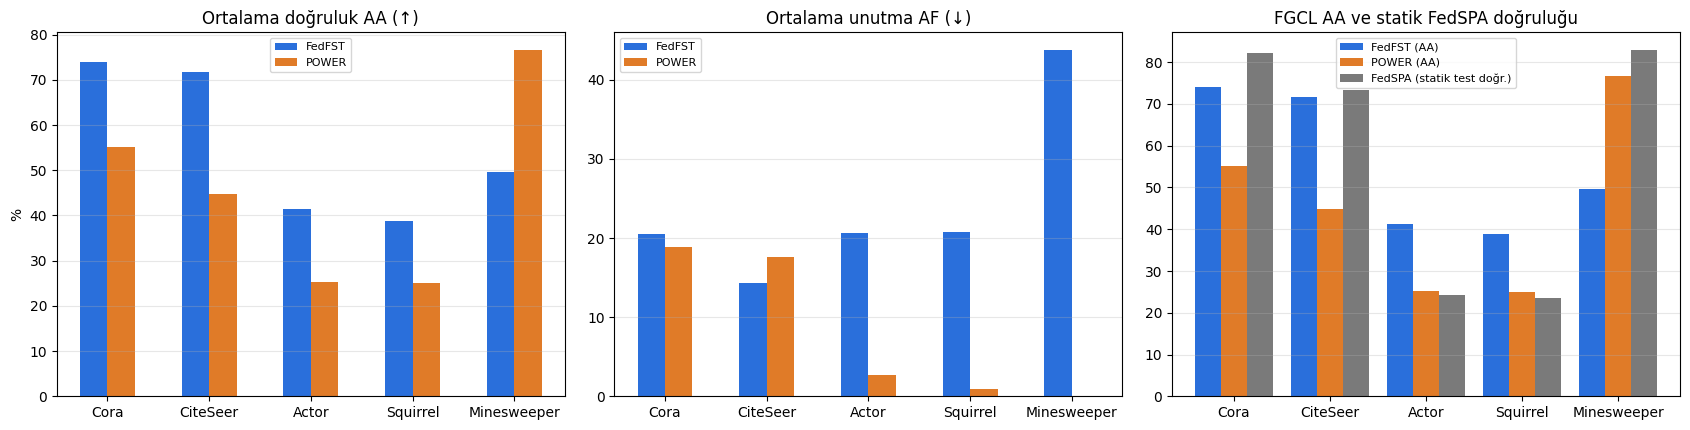

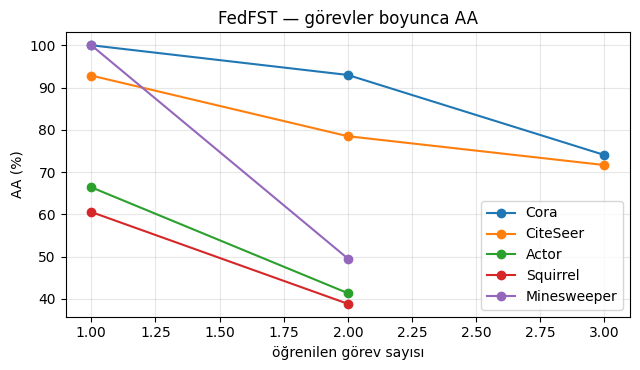

In [ ]:
import matplotlib.pyplot as plt, numpy as np
x = np.arange(len(order)); w = 0.27
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].bar(x - w/2, summary["FedFST AA"], w, label="FedFST", color="#2a6fdb")
ax[0].bar(x + w/2, summary["POWER AA"], w, label="POWER", color="#e07b28")
ax[0].set_title("Ortalama doğruluk AA (↑)"); ax[0].set_ylabel("%")
ax[1].bar(x - w/2, summary["FedFST AF"], w, label="FedFST", color="#2a6fdb")
ax[1].bar(x + w/2, summary["POWER AF"], w, label="POWER", color="#e07b28")
ax[1].set_title("Ortalama unutma AF (↓)"); ax[1].axhline(0, color="k", lw=0.6)
ax[2].bar(x - w, summary["FedFST AA"], w, label="FedFST (AA)", color="#2a6fdb")
ax[2].bar(x, summary["POWER AA"], w, label="POWER (AA)", color="#e07b28")
ax[2].bar(x + w, summary["FedSPA test doğr.*"], w, label="FedSPA (statik test doğr.)", color="#7a7a7a")
ax[2].set_title("FGCL AA ve statik FedSPA doğruluğu")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(order); a.legend(fontsize=8); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("/content/runs/results.png", dpi=130); plt.show()

# FedFST: her görevden sonra o ana kadar görülen görevlerdeki ortalama doğruluk
plt.figure(figsize=(6.5, 3.8))
for d, v in fst_tasks.items(): plt.plot(range(1, len(v) + 1), v, marker="o", label=d)
plt.xlabel("öğrenilen görev sayısı"); plt.ylabel("AA (%)"); plt.title("FedFST — görevler boyunca AA")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

## 9. Değerlendirme

**Özet tablo** (tek tohum, % cinsinden; FGCL için AA ↑ / AF ↓):

| Veri seti | Homofili | FedFST AA | FedFST AF | POWER AA | POWER AF | FedSPA test doğr.* |
|---|---|---|---|---|---|---|
| Cora | yüksek | **74.03** | 20.46 | 55.25 | **18.92** | 82.28 |
| CiteSeer | yüksek | **71.65** | **14.28** | 44.84 | 17.58 | 73.27 |
| Actor | düşük | **41.34** | 20.64 | 25.24 | **2.68** | 24.21 |
| Squirrel | düşük | **38.82** | 20.82 | 25.00 | **0.95** | 23.65 |
| Minesweeper | düşük | 49.53 | 43.80 | **76.69** | **0.00** | 83.01 |

\*FedSPA sürekli öğrenme yapmadığı için AA/AF değil, statik test doğruluğu (en iyi doğrulama turundaki).

### FedFST vs. POWER (aynı problem: FGCL)
* **Ortalama doğruluk:** FedFST beş veri setinin dördünde POWER'dan belirgin biçimde yüksek AA veriyor (Cora +18.8, CiteSeer +26.8, Actor +16.1, Squirrel +13.8 puan). Bu, FedFST'nin sentetik graf üzerinden geçmiş bilgiyi damıtmasının (HHKR + HLST) eski sınıfları korumada işe yaradığını gösteriyor.
* **Heterofilik graflar:** Actor ve Squirrel'de son aşamada 4 sınıf var, yani şans seviyesi ≈ %25. POWER bu iki veri setinde **şans seviyesinde** (25.2 / 25.0) kalıyor; AF'sinin çok düşük olması (2.7 / 0.95) iyi bir unutma direncinden değil, **unutulacak kadar öğrenmemiş olmasından** kaynaklanıyor. FedFST ise iki veri setinde de şansın ~14–16 puan üzerinde; makalenin "yüksek frekans (heterofilik) bilginin korunması" iddiasıyla tutarlı bir sonuç.
* **Unutma:** Homofilik graflarda iki yöntemin AF'si benzer (Cora'da POWER biraz, CiteSeer'de FedFST biraz daha iyi). FedFST'nin AF'si her veri setinde ~14–21 aralığında; yani unutmayı azaltıyor ama ortadan kaldırmıyor. Görevler boyunca AA eğrisi (grafik) her yeni görevde düşüyor.
* **Minesweeper istisnası:** Minesweeper 2 sınıflı ve dengesiz (≈%80 "mayın değil"). Görev başına 1 sınıfla her görev tek sınıf içeriyor; bu ayar sınıf-artımlı öğrenme için **dejenere** (görev 0'da model yalnızca tek sınıf görüyor). FedFST ikinci görevden sonra ilk sınıftaki doğruluğunu %100'den ~%56'ya düşürüyor (AF 43.8); POWER'da ise unutma görülmüyor (AF 0), bunun büyük olasılıkla replay belleğinin ilk sınıfın örneklerini tutmasından kaynaklandığını düşünüyorum. Bu veri setindeki sonucu genel bir üstünlük olarak değil, tek-sınıflı görevlerde replay'in avantajı olarak yorumluyorum.
* **Maliyet:** FedFST, her görevde üreteç eğitimi + sentetik graf optimizasyonu + 200 epoch KD yaptığı için POWER'dan 1.5–4 kat daha yavaş (Cora: 34.6 dk vs 8.4 dk; süreler paralel koşuda ölçüldü).

### FedSPA (statik FGL, referans)
* Homofilik graflarda (Cora 82.3, CiteSeer 73.3) ve Minesweeper'da (83.0) FedSPA'nın tüm sınıfları birlikte görerek ulaştığı doğruluk, FGCL yöntemlerinin AA'sının üzerinde. Bu beklenen bir durum: aradaki fark kabaca "sürekli öğrenmenin bedeli" olarak okunabilir. CiteSeer'de FedFST'nin AA'sı (71.7) bu statik referansa çok yakın.
* Actor ve Squirrel'de ise FedSPA (5 sınıf, şans %20) **şans seviyesine yakın** kalıyor ve en iyi doğrulama turu 1. tur. `lr=0.01` ile tekrarlanan denemede de sonuç değişmedi (7.2), dolayısıyla sorun yalnızca öğrenme oranı değil. 3 istemcili bu ayarda ve sabit varsayılan hiperparametrelerle FedSPA'nın bu iki veri setinde öğrenemediğini gözlemledim; makaledeki ayardan (10 istemci, farklı veri setleri) farklı olduğumu da not ediyorum.

### Karşılaştırmanın sınırlılıkları
1. **Veri bölmeleri farklı:** FedFST 0.6/0.2/0.2, POWER veri setine göre 0.2/0.4/0.4 (Cora/CiteSeer/Actor) bölmesi kullanıyor; yani FedFST Cora'da **yaklaşık 3 kat daha fazla etiketli eğitim düğümü** görüyor. FedFST'nin AA farkının bir kısmı buna bağlı olabilir. Her yöntemi kendi resmi ayarıyla çalıştırmayı tercih ettim; aynı bölmeyle yeniden karşılaştırmak daha adil bir sonraki adım olur.
2. **Tek tohum:** Süre nedeniyle her koşu bir kez yapıldı. Hazırlık sırasında aynı ayarla POWER Cora'da AA 58.08 ölçmüştüm, bu koşuda 55.25 çıktı; yani tohum/donanım kaynaklı ±3 puanlık oynama var. 3–5 tohum ortalaması daha güvenilir olurdu.
3. **AA/AF hesaplamaları** iki kod tabanında kendi fonksiyonlarıyla yapılıyor; tanım aynı olsa da değerlendirme kümesi (bölme) farklı.
4. FedSPA farklı bir problemi çözdüğü için doğrudan sıralamaya katılmamalı; tabloda yalnızca statik bir referans olarak yer alıyor.

**Sonuç:** Bu deney koşullarında FedFST, FGCL'de POWER'dan özellikle homofilik ve heterofilik çok-sınıflı graflarda (Cora, CiteSeer, Actor, Squirrel) daha yüksek ortalama doğruluk elde etti; buna karşın daha yavaş ve tek-sınıflı görevlerden oluşan Minesweeper ayarında POWER'ın replay tabanlı yaklaşımı unutmaya karşı daha dayanıklıydı.

## 10. Karşılaşılan hatalar ve çözümleri (özet)

| Kod | Hata / sorun | Neden | Çözüm |
|---|---|---|---|
| FedFST | `ModuleNotFoundError: No module named 'datasets.dataset_loader'` | repo klasörlerinde `__init__.py` yok; Colab'daki HuggingFace `datasets` paketi önce bulunuyor | boş `__init__.py` dosyaları |
| FedFST | `ImportError: cannot import name 'edge_distribution_low1'` | `Ours.py` utils'te olmayan iki fonksiyonu import ediyor | kullanılmadıkları için importtan çıkarıldı |
| FedFST | `AttributeError: 'Namespace' object has no attribute 'kd_ce_weight'` (ve 2 argüman daha) | `args.py`'de tanımsız | kodun kendi `getattr` varsayılanlarıyla eklendi |
| FedFST | `torch_sparse` kurulamıyor | Colab'daki torch sürümü için tekerlek yok; modül zaten kullanılmıyor | import kaldırıldı |
| FedFST | Squirrel / Minesweeper desteklenmiyor | yükleyicide yok | PyG yükleyicileri eklendi |
| FedFST | kenar budama çok yavaş | kenar başına Python döngüsü ve `.item()` | vektörel eşdeğeri |
| FedFST | `device_id` varsayılanı 2 | yazarların çoklu GPU makinesi | `--device_id 0` |
| POWER | yalnızca 300 denemelik Optuna araması, CPU | `optuna_search.py` | `run_power.py` (tek koşu, GPU) |
| POWER | `UnpicklingError` (`weights_only`) | PyTorch ≥ 2.6 `torch.load` varsayılanı | `TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1` |
| POWER | Minesweeper bölme oranı yok | `data.py` | Roman-empire ile aynı 0.5/0.25/0.25 |
| FedSPA | DGL kurulamıyor | Colab torch sürümü için DGL tekerleği yok | `uv` ile Python 3.11 + torch 2.4 + DGL sanal ortamı |
| FedSPA | `TypeError: Bad graph type, use only non directed graph` (Actor, Squirrel) | yönlü graf, Louvain yönsüz ister | `to_undirected` |
| FedSPA | `ValueError: Sum of the elements is zero, cannot normalize.` (Squirrel) | HBDA'da Fisher farklarının toplamı sıfır → sıfıra bölme | farklar sıfır/eşitse eşit ağırlık (yama 5), yeniden koşu |
| FedSPA | `ValueError: All the received local models have parameters of nan value.` (Cora, ilk koşu) | ilk turda sayısal patlama; aynı ayarla tekrar edilemedi | aynı ayarlarla yeniden koşu |
| FedSPA | `argument --lr_scheduler: invalid int value` | flgo `sys.argv`'ı da ayrıştırıyor, `--lr` kısaltması çakışıyor | argüman adı `--spa_lr` |
| FedSPA | `libnvrtc.so.12` bulunamadı | DGL sparse, CUDA runtime'ı sistemde arıyor | `LD_LIBRARY_PATH`'e pip'in NVIDIA kütüphaneleri |
| FedSPA | matplotlib backend hatası (`module://matplotlib_inline...`) | Colab'ın `MPLBACKEND` değeri sanal ortamda yok | `MPLBACKEND=Agg` |
| FedSPA | veri seti ve model boyutları Cornell'e sabit, 3 veri seti eksik, test doğruluğu loglanmıyor | repo tek deney için yazılmış | `patch_fedspa.py` + `run_fedspa.py` |
| FedSPA | `Failed to save logger.output` uyarısı | görev klasöründe `record/` yok | klasör oluşturuluyor (zararsız uyarı) |
| Colab | hücre durdurulunca `!python ...` süreçleri durmuyor | `!` alt kabuğu kesmeyi iletmiyor | uzun koşular `nohup` + log dosyası ile |

### Kaynaklar
* FedFST — <https://github.com/YunQi572/FedFST> (Guo vd., SIGKDD 2026)
* POWER — Zenodo kayıt 15487655, `zyl24/FCGL_POWER` (Zhu vd., KDD 2025); OpenFGL — <https://github.com/xkLi-Allen/OpenFGL>
* FedSPA — <https://github.com/OakleyTan/FedSPA> (Tan vd., CVPR 2025)